# 07 FMF detections: how the grid alignment works, and what the detections look like

Notebook 06 compared two FMF runs (both at Haenam's 12×MAD with the 0.20 floor):
- **Frozen:** the Haenam code exactly.
- **Aligned:** every day trace shifted onto the exact 10 ms sample grid before templates are cut and data are scanned.

This notebook does two things:
1. It shows, with the real sample times of three Imsil stations, why the frozen code compares a template with the wrong sample at the HG stations, and what the alignment changes (section 1).
2. It shows real detections of the final catalog (aligned code, 10×MAD, no floor; decisions D20 and D23) in sections 2–4, with Haenam's own views:
   - where they fall in time;
   - the detection set (record section with the template windows and the detector's view) and the full-waveform comparison, for a strong, a typical and a near-threshold detection, and for the one detection before the swarm;
   - the repeater gathers at two stations.

In [1]:
import os, sys, importlib.util
import numpy as np, pandas as pd
from IPython.display import Image, display
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; FA = f'{DL}/fmf_aligned'
# the final run's environment (aligned code, 10 x MAD, no floor), as run_imsil_5_20H.sh + run_full_period.sh export it
os.environ.update(FMF_RUN='imsil_5_20H_aligned_mad10', FMF_MAD_K='10', FMF_CC_FLOOR='0', FMF_BAND='5,20', FMF_STATION_LIST=f'{FA}/stations_imsil_5_20H.csv', FMF_SEQUENCES='imsil',
                  FMF_TEMPLATE_CSV='imsil_templates_ref25.csv', MAD_SEGMENTED='1', FMF_SNR_MIN='1.2', FMF_MAD_SUBSAMPLE='8', FMF_STEP='1',
                  FMF_WORKERS='16', FMF_GPU_BUDGET='12e9', HELVETICA_DIR='/home/msseo/Download/Helvetica')
sys.path.insert(0, FA)
import config as C, scan, similarity as S
C.CATALOG_CSV = f'{DL}/catalogs/fmf_final/imsil_fmf_catalog.csv'   # the final catalog (decisions D20, D23: aligned code, 10 x MAD, no floor)
# the loader's worker processes are started fresh (forkserver) instead of forked from this kernel: forked workers die on PAGO
# (BrokenProcessPool, the same failure as the multi-day scans); the computation is unchanged
import functools, multiprocessing as mp, concurrent.futures as cf
scan.ProcessPoolExecutor = functools.partial(cf.ProcessPoolExecutor, mp_context=mp.get_context('forkserver'))
spec = importlib.util.spec_from_file_location('plotstyle', f'{DL}/pipeline/plotstyle.py'); plotstyle = importlib.util.module_from_spec(spec); spec.loader.exec_module(plotstyle)
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from obspy import read, UTCDateTime
FIG = f'{DL}/notebooks/figs_07'; os.makedirs(FIG, exist_ok=True)
sh = S.load_shelly(); ev = [str(e) for e in sh['event_id']]; cusp = list(sh['cuspid'].astype(int))
cat = pd.read_csv(C.CATALOG_CSV, parse_dates=['origin'])
tpl = pd.read_csv(f'{DL}/catalogs/imsil_templates_ref25.csv', dtype={'event_id': str}, parse_dates=['origin_time_UTC'])
kma = pd.read_csv(f'{DL}/catalogs/imsil_kma24.csv', dtype={'event_id': str}, parse_dates=['origin_time_UTC'])
print(f'final catalog: {len(cat)} detections ({int(cat.is_reference.sum())} reference, {int(cat.is_new.sum())} new); catalog {C.CATALOG_CSV}')

final catalog: 235 detections (28 reference, 207 new); catalog /home/msseo/works/72.2025_Imsil_swarm/DL_detection/catalogs/fmf_final/imsil_fmf_catalog.csv


## 1. Why the frozen code slips, and what the alignment does
The ML 1.9 template (event 20251102203835) is used here. Its windows all start on one common time grid, set by its earliest pick: IMSB's P, which reaches the template builder rounded to the millisecond, 8.0 ms past a 10 ms tick.

The figure shows the real sample instants of three stations around the start of the template's first window:
- IMSB (HH) samples 8.4 ms past each tick;
- MALA (HG) samples 3.1 ms past each tick;
- SUCA (HG) samples on the tick.

For each station, two samples are marked:
- **circle:** the sample where its template window was cut, the channel's own sample nearest the window start;
- **cross:** the sample the scanner compares it with. The scanner rounds the window start to the nearest index of the day array, and that index points at this channel's sample.

**Top panel (frozen):** IMSB and SUCA agree. At MALA the nearest own sample to 8.0 ms is the one at 3.1 ms (4.9 ms back, against 5.1 ms forward), but the scanner's index lands on the next sample, 13.1 ms. The template is therefore compared with data shifted by one sample (10 ms). At 5–20 Hz that costs about 20 % of the correlation on every HG channel, for every detection of this template.

**Bottom panel (aligned):** every trace is first shifted onto the ticks by Lanczos interpolation, a band-limited sub-sample shift with relative error about 10⁻⁴. The nearest sample and the scanner's index are then always the same sample.

Neither Beaucé's `fast_matched_filter` nor EQcorrscan 0.4.3 interpolates traces onto a common grid. FMF is only the correlation kernel and takes integer moveouts on arrays it assumes share one sample clock. Keeping templates and data on one clock is the job of the code around it, in this pipeline `templates.py`, `shelly.py` and `scan.py`.

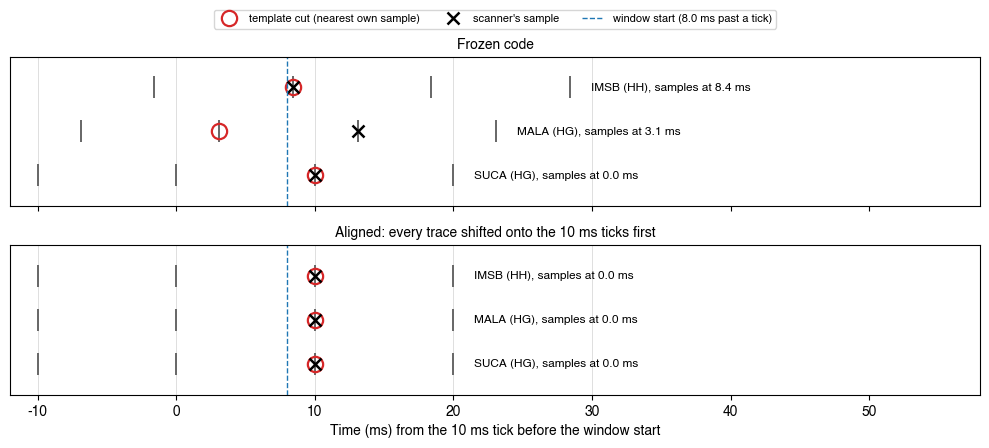

In [2]:
ti = ev.index('20251102203835'); o = UTCDateTime(str(sh['origin_utc'][ti])); day0 = UTCDateTime(o.date)
ws = o + float(sh['ref_s'][ti])                              # start of the template's first window (the common grid)
F = ((ws - day0) * C.FS) % 1
def grid_offset(net, sta, cha):
    f = sorted(__import__('glob').glob(f'{C.CONTINUOUS}/{net}/{sta}/{cha}.D/*.D.{o.year}.{o.julday:03d}'))[0]
    tr = read(f, headonly=True)[0]; return ((tr.stats.starttime - day0) * C.FS) % 1
chans = [('KS', 'IMSB', 'HHZ'), ('KS', 'MALA', 'HGZ'), ('KS', 'SUCA', 'HGZ')]
fig, axs = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
for ax, aligned in zip(axs, (False, True)):
    for y, (net, sta, cha) in enumerate(chans[::-1]):
        f = 0.0 if aligned else grid_offset(net, sta, cha)
        k0 = np.floor((ws - day0) * C.FS)                     # day-grid tick just before the window start
        samples = (k0 + np.arange(-1, 3) + f)                 # this channel's sample instants (in day samples)
        cut = samples[np.argmin(np.abs(samples - (ws - day0) * C.FS))]
        f_eff = f if f < 0.5 else f - 1                        # obspy trim to the nearest sample: index 0 is the sample nearest day start
        scan_idx = np.round((ws - day0) * C.FS)                # the scanner's index of the window start
        cmp_ = scan_idx + f_eff                                # the sample at that index of this channel's array
        ms = lambda x: (x - k0) * 10
        ax.plot(ms(samples), np.full(len(samples), y), '|', color='0.4', ms=16, mew=1.4)
        ax.plot(ms(cut), y, 'o', mfc='none', mec='tab:red', ms=11, mew=1.6, label='template cut (nearest own sample)' if y == 0 else None)
        ax.plot(ms(cmp_), y, 'x', color='black', ms=9, mew=1.8, label="scanner's sample" if y == 0 else None)
        ax.text(ms(samples[-1]) + 1.5, y, f'{sta} ({cha[:2]}), samples at {f * 10:.1f} ms' + ('' if np.isclose(cut, cmp_) else '  ← one sample off'), va='center', fontsize=8.5,
                color='tab:red' if not np.isclose(cut, cmp_) else 'black')
    ax.axvline(F * 10, color='tab:blue', lw=1, ls='--', label=f'window start ({F * 10:.1f} ms past a tick)')
    for t_ in range(-10, 31, 10): ax.axvline(t_, color='0.85', lw=0.6, zorder=0)
    ax.set_yticks([]); ax.set_ylim(-0.7, 2.7); ax.set_title('Frozen code' if not aligned else 'Aligned: every trace shifted onto the 10 ms ticks first', fontsize=10)
axs[1].set_xlabel('Time (ms) from the 10 ms tick before the window start'); axs[1].set_xlim(-12, 58)
axs[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.15), ncol=3, frameon=True, fontsize=8)
plt.tight_layout(); plt.show()

## 2. The aligned detections in time
Each detection is shown with its network CC. KMA origins are marked along the top.

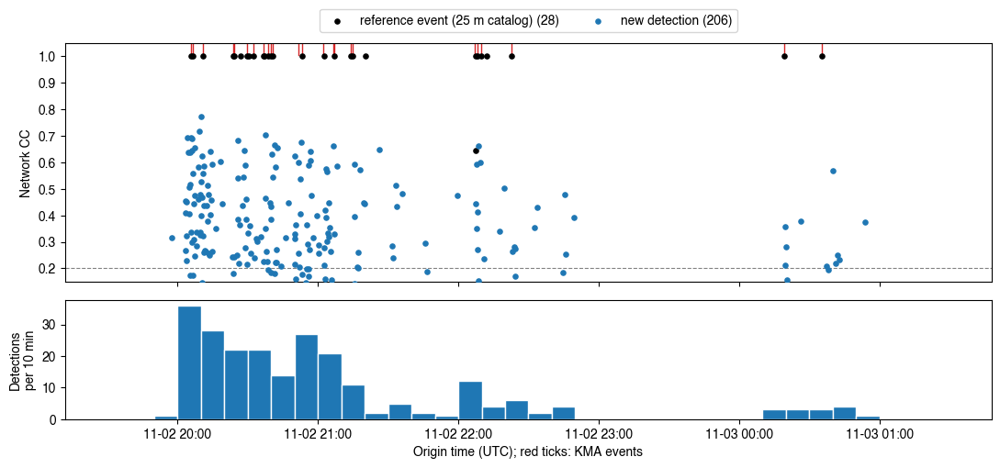

swarm-window detections: 234; first 2025-11-02 19:57:38.092002, last 2025-11-03 00:53:41.762000; outside this window in the whole period: 1


In [3]:
sw = cat[cat.origin.between('2025-11-02 19:30', '2025-11-03 01:30')]
fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for lab, m, col in (('reference event (25 m catalog)', sw.is_reference, 'black'), ('new detection', sw.is_new, 'tab:blue')):
    ax[0].scatter(sw.origin[m], sw.cc[m], s=14, color=col, label=f'{lab} ({int(m.sum())})', zorder=3)
for t_ in kma.origin_time_UTC: ax[0].axvline(t_, ymin=0.95, ymax=1, color='tab:red', lw=1)
ax[0].axhline(0.2, color='0.5', lw=0.8, ls='--'); ax[0].set_ylabel('Network CC'); ax[0].set_ylim(0.15, 1.05)
ax[0].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True)
bins = pd.date_range('2025-11-02 19:30', '2025-11-03 01:30', freq='10min')
ax[1].hist(sw.origin, bins=bins, color='tab:blue', edgecolor='white'); ax[1].set_ylabel('Detections\nper 10 min')
ax[1].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M')); ax[1].set_xlabel('Origin time (UTC); red ticks: KMA events')
plt.tight_layout(); plt.show()
print(f'swarm-window detections: {len(sw)}; first {sw.origin.min()}, last {sw.origin.max()}; outside this window in the whole period: {len(cat) - len(sw)}')

## 3. Detection sets: the record, the template windows and the detector's view
These are Haenam's per-detection views (`band_event_figs.py`), drawn with the same functions of `similarity.py`.

**Detection set.** Every live channel of the detecting template is shown as a row, ordered by distance from the template event:
- the record (gray), from 1.5 s before the predicted P to 3 s after the predicted S;
- the template's P window (red) and S window (blue) laid over it in place, each labelled with its own correlation;
- below, the detector's view: the template's network CC over the whole day and ±12 s around the detection, with the 12×MAD threshold and the 0.20 floor.

**Full waveforms.** For the best stations, the template event's record (black) over the detection's record (red) on the same span, P through S coda.

**Why IMSB.Z is often missing.** A row appears only where the template has a live window. IMSB's P window is live in only 17 of the 28 templates:
- 4 templates have no IMSB P pick (PhaseNet+ made none);
- 7 more have an IMSB P window weaker than 1.2× the noise before it, so the frozen S/N gate drops that channel at scan time.

IMSB sits almost due north of the swarm (azimuth 354°), with a takeoff about 27° from vertical, nearly perpendicular to the vertical east–west plane. Strike-slip on that plane would put IMSB close to a P nodal direction. That would explain a weak P beside a strong S, as the gathers show, but no focal mechanism has been determined yet. IMSB's S windows, on N and E, are live in every template but one.

Four detections are shown:
- the strongest new detection;
- a typical one (median CC);
- the weakest;
- the single detection before the swarm (2025-11-02 19:57:38).

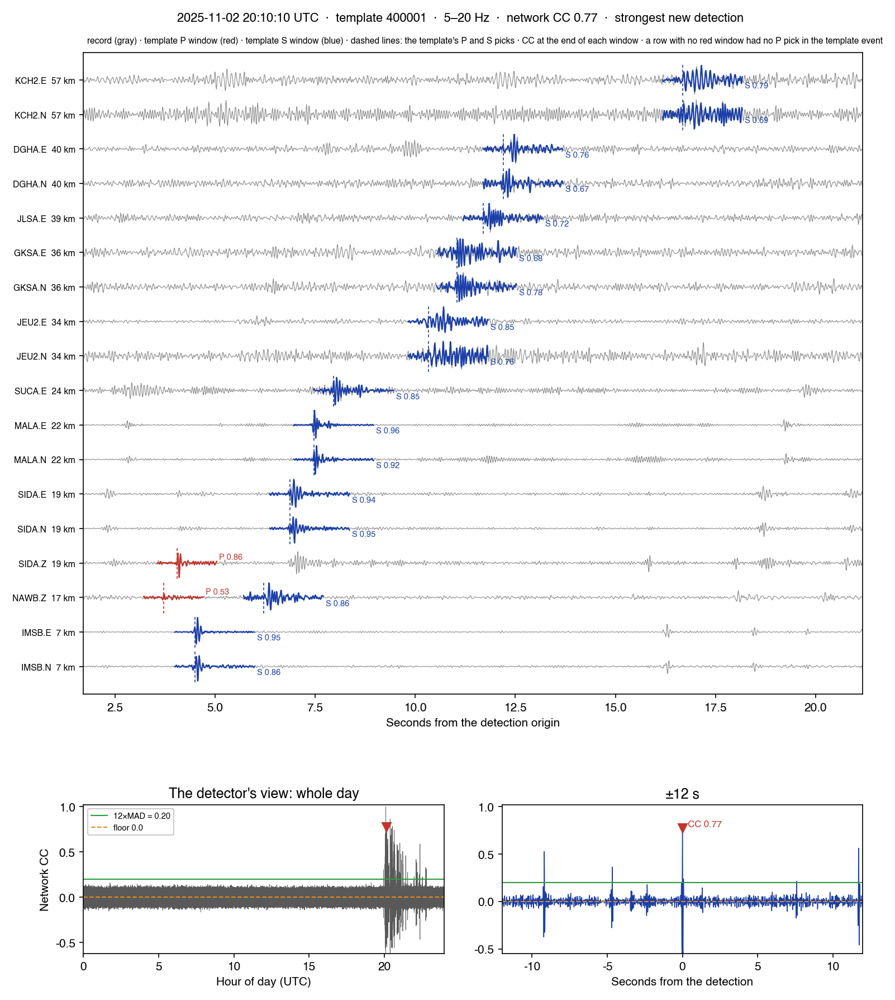

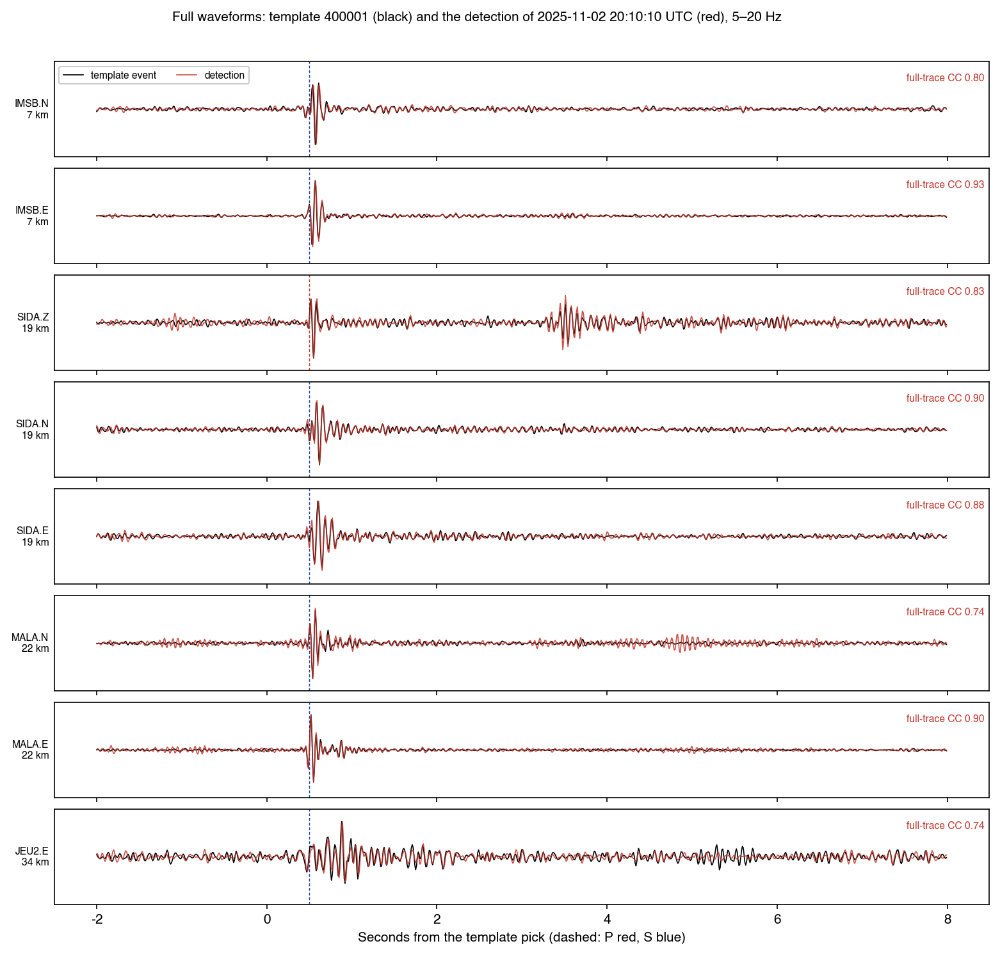

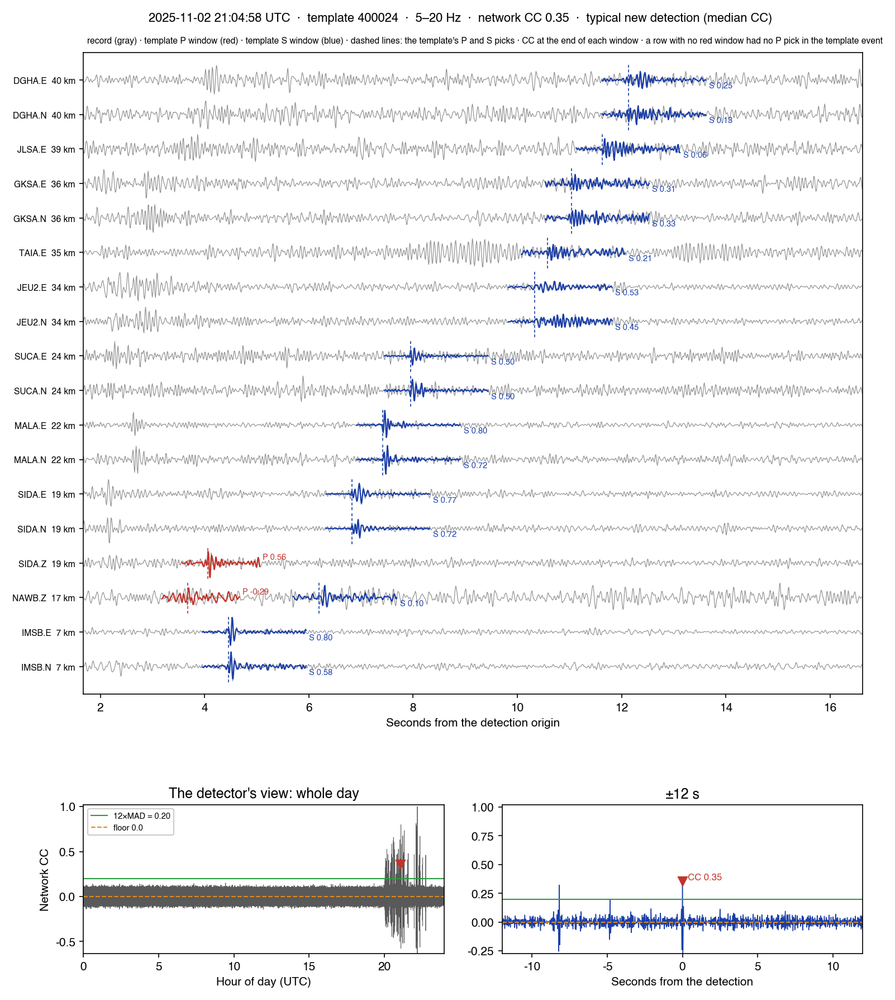

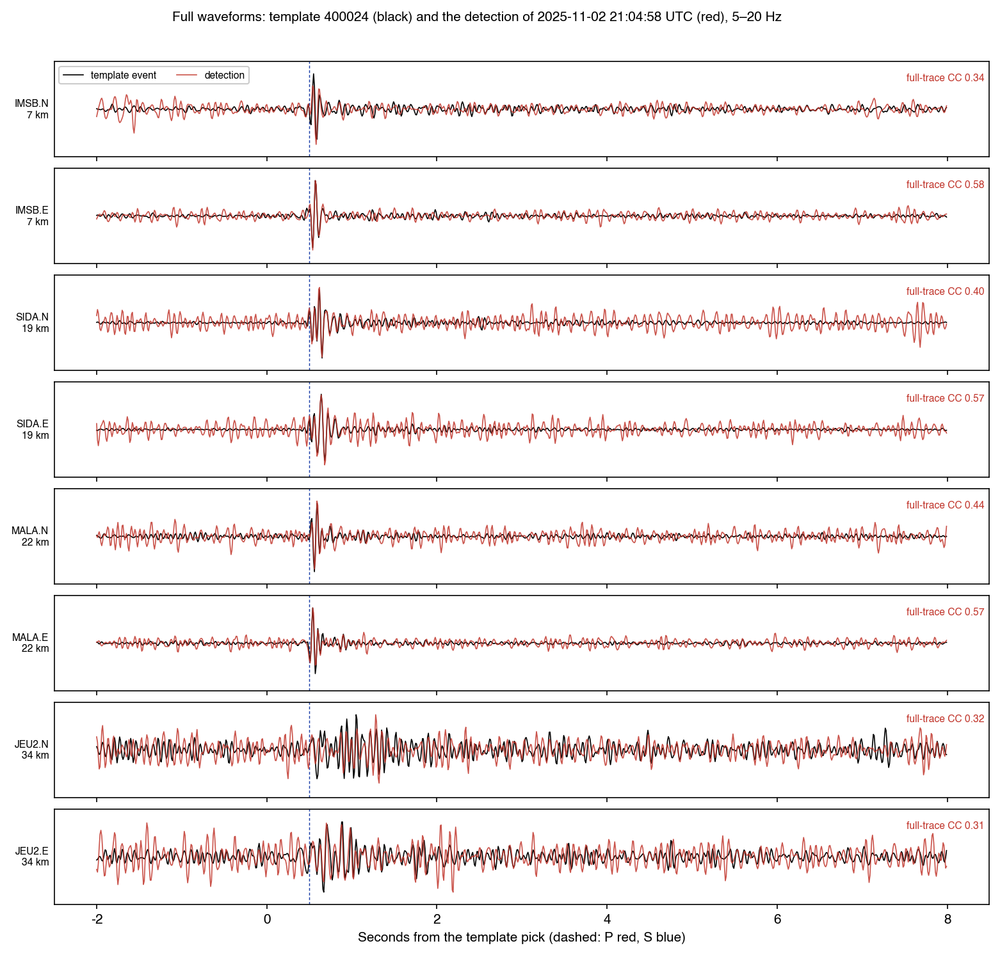

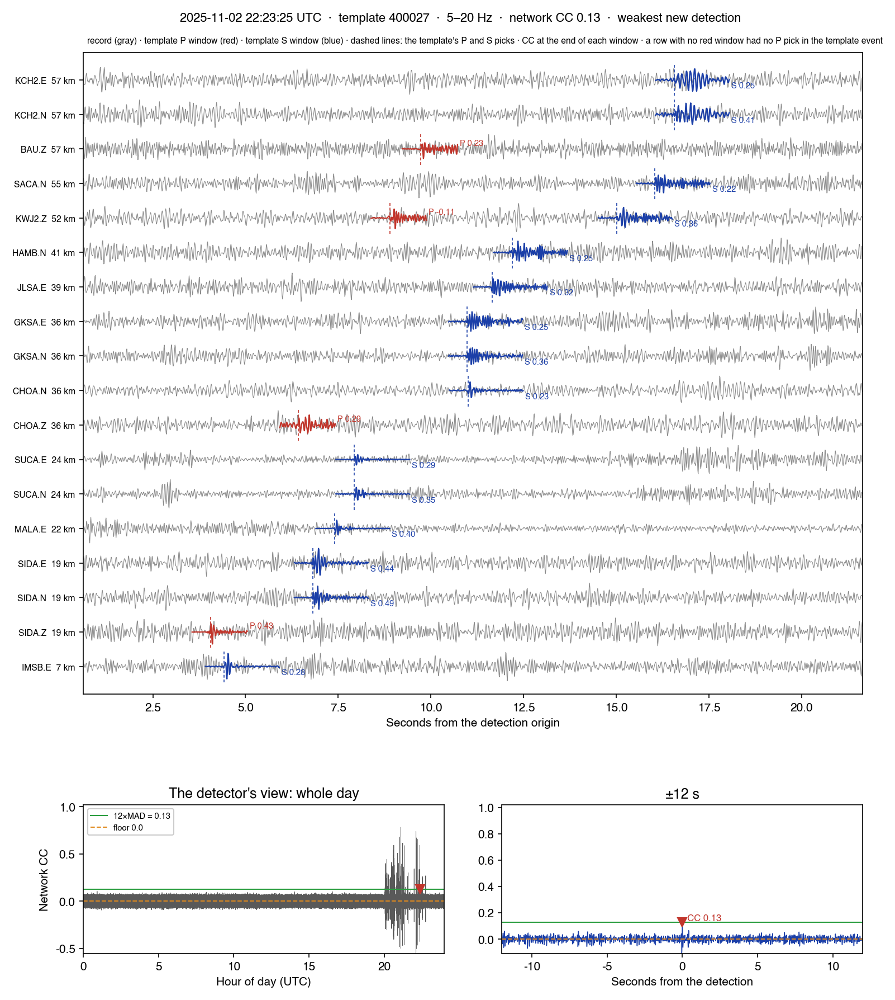

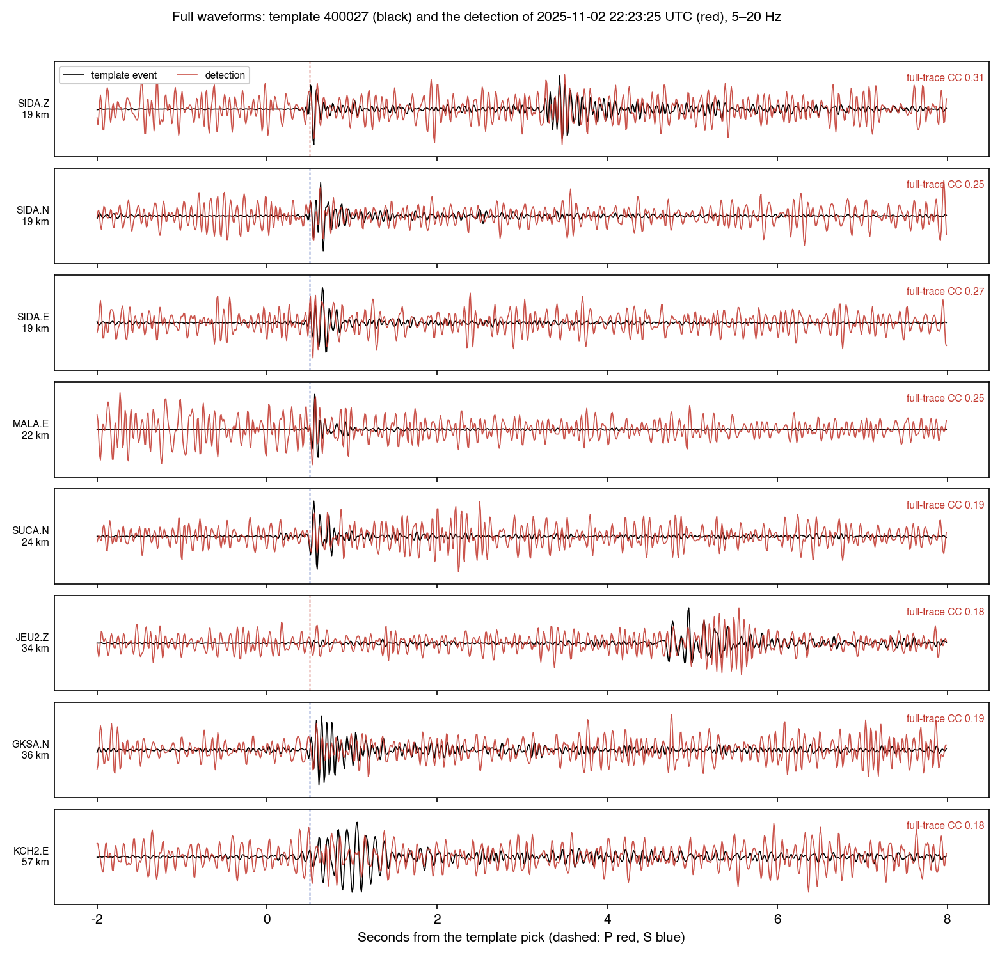

8639801 correlation computations were skipped on the 0-th template. Can be caused by zeros in data, or too low amplitudes (try to increase the gain).


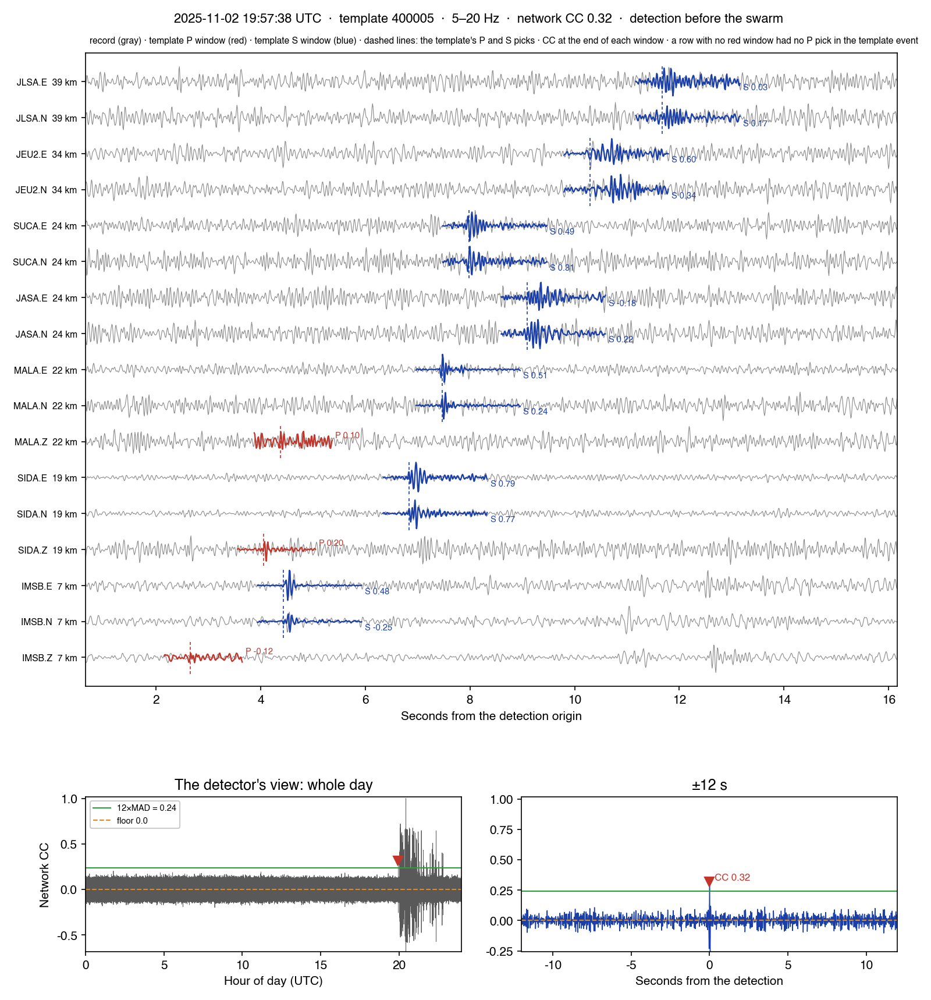

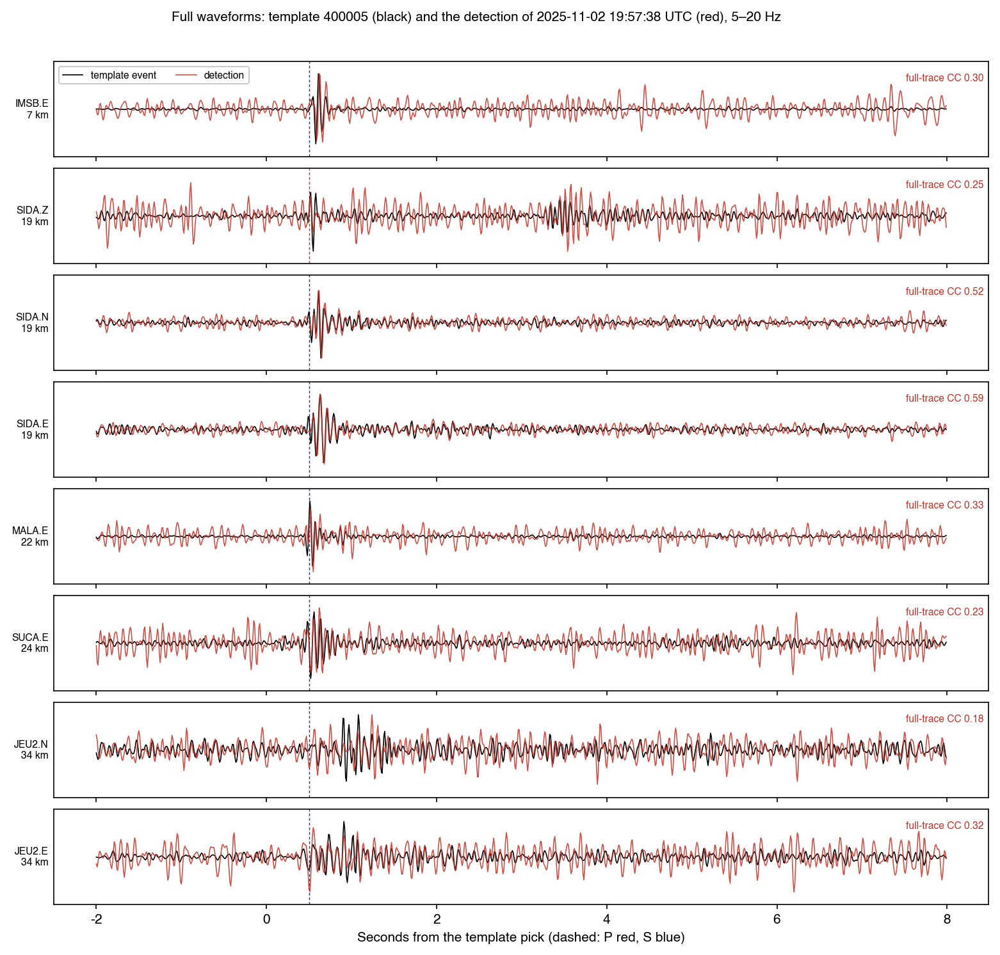

,example,origin,template,catalog_cc,recomputed_cc,channels,day_threshold
0,strongest new detection,2025-11-02 20:10:10.012001,400001,0.771,0.771,23,0.201
1,typical new detection (median CC),2025-11-02 21:04:58.272000,400024,0.352,0.352,24,0.197
2,weakest new detection,2025-11-02 22:23:25.892001,400027,0.129,0.129,59,0.129
3,detection before the swarm,2025-11-02 19:57:38.092002,400005,0.316,0.316,17,0.241


In [4]:
new = cat[cat.is_new].sort_values('cc')
pre = cat[cat.origin < pd.Timestamp('2025-11-02 20:00')]
examples = [('strongest new detection', new.iloc[-1]), ('typical new detection (median CC)', new.iloc[len(new) // 2]), ('weakest new detection', new.iloc[0])] + [('detection before the swarm', r) for _, r in pre.iterrows()]
loc0 = tpl.set_index('cuspid'); days = {}; band = f'{C.BANDPASS[0]:g}–{C.BANDPASS[1]:g} Hz'; shown = []
for label, r in examples:
    det = pd.Timestamp(r.origin); c = int(r.template_cuspid); k = cusp.index(c); lat, lon = loc0.loc[c, ['latitude', 'longitude']]
    if det.dayofyear not in days: days[det.dayofyear] = scan.load_day([str(s) for s in sh['stations']], [str(p) for p in sh['channels']], det.year, det.dayofyear)
    day = days[det.dayofyear]; ch, net, mean = S.detection_vs_template(sh, k, r.origin, present=day[1]); res = S.template_cc_day(sh, k, det.year, det.dayofyear, day=day)
    stem = f'{FIG}/{det:%Y%m%d_%H%M%S}_{c}'
    S.plot_detection_set(sh, k, r.origin, ch, f'{det:%Y-%m-%d %H:%M:%S} UTC  ·  template {c}  ·  {band}  ·  network CC {net:.2f}  ·  {label}', stem + '_set.png', res=res, tpl_lat=lat, tpl_lon=lon)
    S.plot_full_trace_comparison(sh, k, r.origin, f'Full waveforms: template {c} (black) and the detection of {det:%Y-%m-%d %H:%M:%S} UTC (red), {band}', stem + '_full.png', tpl_lat=lat, tpl_lon=lon)
    shown.append(dict(example=label, origin=det, template=c, catalog_cc=round(r.cc, 3), recomputed_cc=round(net, 3), channels=len(ch), day_threshold=round(res['thr'], 3) if res else np.nan))
    for suf in ('set', 'full'): display(Image(f'{stem}_{suf}.png'))
shown = pd.DataFrame(shown); display(shown)

## 4. Every detection of one template at one station
This is Haenam's repeater gather (`station_gather.py`, unchanged). Every swarm detection of the template that represents the most detections is stacked in time order at one station, each aligned on that template's P pick. The template is on top; red marks the template's own event, blue a new detection, gray a reference event.

The number on each trace is its correlation with the template on that component. Two stations are shown: IMSB, the nearest (7 km), and SIDA (19 km).

40 detections x 3 components at KS.IMSB -> /home/msseo/works/72.2025_Imsil_swarm/DL_detection/notebooks/figs_07/gather_400005_IMSB.png


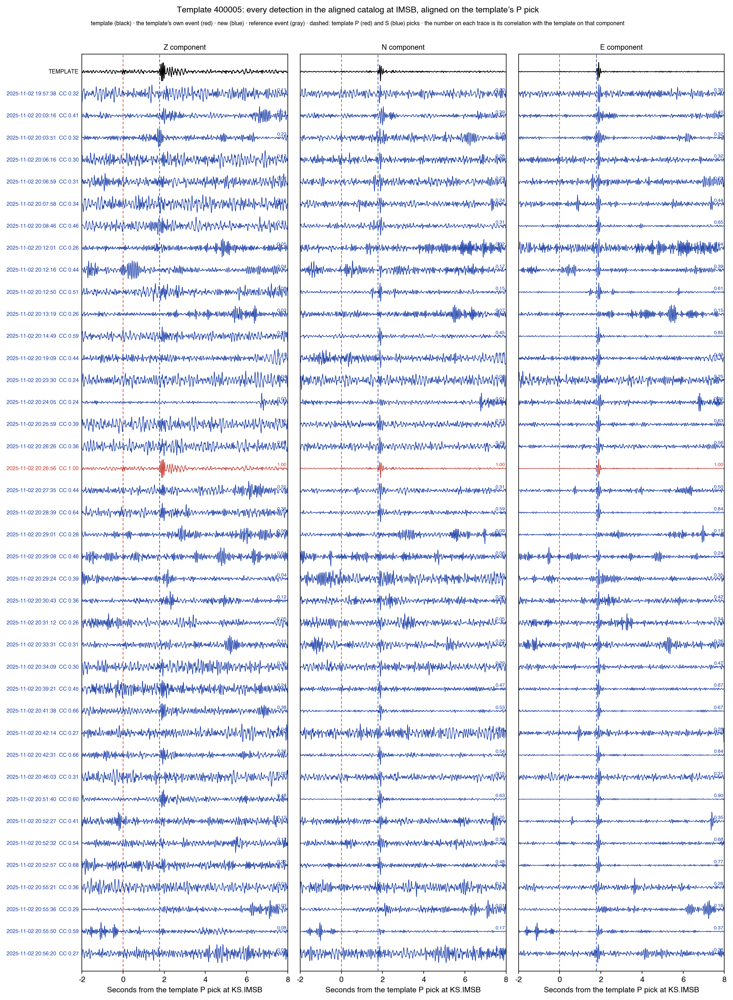

40 detections x 3 components at KS.SIDA -> /home/msseo/works/72.2025_Imsil_swarm/DL_detection/notebooks/figs_07/gather_400005_SIDA.png


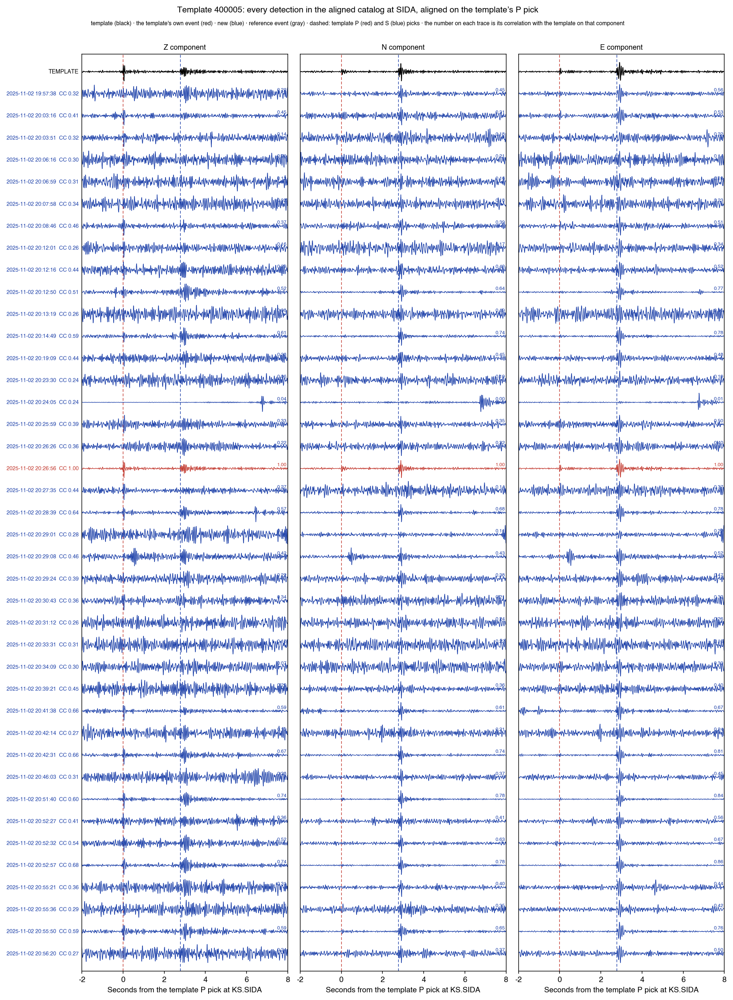

In [5]:
import station_gather as G
top = int(cat.template_cuspid.value_counts().idxmax())
for sta in ('KS.IMSB', 'KS.SIDA'):
    png = f'{FIG}/gather_{top}_{sta.split(".")[1]}.png'
    G.station_gather(top, sta, '2025-11-02 19:00', '2025-11-03 02:00', png, title=f'Template {top}: every detection in the aligned catalog at {sta.split(".")[1]}, aligned on the template’s P pick', same_template=True)
    display(Image(png))

## Comprehensive summary

In [6]:
summary = pd.DataFrame([
    ('Aligned run: detections (reference / new)', f'{len(cat)} ({int(cat.is_reference.sum())} / {int(cat.is_new.sum())})'),
    ('Detections in 2025-11-02 19:30 - 11-03 01:30 / elsewhere in Sep 2025 - Jan 2026', f'{len(sw)} / {len(cat) - len(sw)}'),
    ('Template representing the most detections', f'{top} ({ev[cusp.index(top)]}): {int((cat.template_cuspid == top).sum())}'),
    ('Shown detections: catalog vs recomputed network CC', '; '.join(f'{r.origin:%H:%M:%S} {r.catalog_cc:.2f}/{r.recomputed_cc:.2f}' for r in shown.itertuples())),
], columns=['quantity', 'value'])
display(summary)
print('Take-home points')
print('  - In the frozen code a template is cut at the nearest sample of its own channel but scanned at the rounded day-grid index; at stations sampling 3.1 ms past each tick the two differ by one sample. The aligned code removes the difference by shifting every trace onto the 10 ms grid first.')
print(f'  - The final catalog holds {len(cat)} detections ({int(cat.is_new.sum())} beyond the {int(cat.is_reference.sum())} reference events), {len(sw)} of them in 2025-11-02 19:30 - 11-03 01:30 and {len(cat) - len(sw)} later on Nov 3 ({", ".join(f"{t:%H:%M:%S}" for t in cat.origin[~cat.origin.isin(sw.origin)])}); none elsewhere in Sep 2025 - Jan 2026.')
print('  - The detection sets show the template windows on the continuous record: the strongest detections repeat the template waveform at every station; the weakest lie near the 10 x MAD threshold and are vetted in notebooks 08 and 09.')

,quantity,value
0,Aligned run: detections (reference / new),235 (28 / 207)
1,Detections in 2025-11-02 19:30 - 11-03 01:30 /...,234 / 1
2,Template representing the most detections,400005 (20251102202656): 51
3,Shown detections: catalog vs recomputed networ...,20:10:10 0.77/0.77; 21:04:58 0.35/0.35; 22:23:...


Take-home points
  - In the frozen code a template is cut at the nearest sample of its own channel but scanned at the rounded day-grid index; at stations sampling 3.1 ms past each tick the two differ by one sample. The aligned code removes the difference by shifting every trace onto the 10 ms grid first.
  - The final catalog holds 235 detections (207 beyond the 28 reference events), 234 of them in 2025-11-02 19:30 - 11-03 01:30 and 1 later on Nov 3 (04:23:32); none elsewhere in Sep 2025 - Jan 2026.
  - The detection sets show the template windows on the continuous record: the strongest detections repeat the template waveform at every station; the weakest lie near the 10 x MAD threshold and are vetted in notebooks 08 and 09.
